<img src=https://courseware.decoded.com/images/decoded/logo-decoded.png align=left width=100px/>

# M08 ML Classification Capstone Template
---
<small>© 2026 Decoded Limited. All rights reserved. Website: https://decoded.com </small>

In this notebook we provide a guide/template that you can use for your capstone. This template is SPECIFICALLY for Binary Classification refer to the other templates if your tasks is Regression or Time Series

In [ ]:
# Install dependencies (uncomment if running for the first time in this environment)
#!pip install ydata-profiling pycaret
#pip install optuna

## 0. Loading Your Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
from sklearn.model_selection import train_test_split

In [6]:
#Loading the dataset
from sklearn.datasets import fetch_openml
df = fetch_openml("adult",version=2,as_frame=True)

#### What does this dataset contain?

## 1. Loading the Data
We will load and inspect the head

In [7]:
df.head()

AttributeError: head

Identitfy and inspect the Binary Target (the thing we wish to predict)

In [5]:
df["class"].value_counts()

TypeError: Cannot index by location index with a non-integer key

just eyeball at the moment no analysis at this point

## 2. Generating the Profile Reports
Instead of writing dozens of `df.describe()` and `df.hist()` commands, we pass our dataframes into `ProfileReport`.

*Note: To save memory in the notebook, we will display the ex report interactively, but export the Insurance report as an HTML file.*

In [ ]:
# --- Profile the Insurance Dataset ---
ex_profile = ProfileReport(df, title="EDA Report Classification", explorative=True)
ex_profile.to_notebook_iframe()

# Display the EDA as a html report


Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 15/15 [00:00<00:00, 1474.44it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Use the overview pane the first pane to guide our data checks

### 0. Data Familiarization (Sanity Check)

What is the shape of the data?
→ Determines scale and modeling constraints
→ ✅ Choose model complexity, validation strategy

In [ ]:
# Shape of data (rows, columns)
df.shape

(48842, 15)

Comments on shape:

Potential considerations:

What is the shape of the data?
do you have a small dataset?

In [ ]:
df.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,class
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,NaN,103497,Some-college,10,Never-married,NaN,Own-child,White,Female,0,0,30,United-States,<=50K


comments on the head:

potential actions:

What does a sample look like?
- Reveals structure and obvious issues
- Identify target, IDs, feature types

In [ ]:
# Data types
df.dtypes

age                  int64
workclass         category
fnlwgt               int64
education         category
education-num        int64
marital-status    category
occupation        category
relationship      category
race              category
sex               category
capital-gain         int64
capital-loss         int64
hours-per-week       int64
native-country    category
class             category
dtype: object

comments on dtypes:


potential considerations:

Are data types correct?
-  Affects all downstream processing
- Fix dtypes later on, separate feature groups

do we have outliers/anomalies?

In [ ]:
# Data types
df.describe()

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
count,48842.000000,4.884200e+04,48842.000000,48842.000000,48842.000000,48842.000000
mean,38.643585,1.896641e+05,10.078089,1079.067626,87.502314,40.422382
std,13.710510,1.056040e+05,2.570973,7452.019058,403.004552,12.391444
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.175505e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.781445e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.376420e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.490400e+06,16.000000,99999.000000,4356.000000,99.000000


comments on values considering the min and maxes in particular:

any potential actions:

Any obvious anomalies?
- Early detection of data issues
- Flag problems for deeper analysis later

## EDA informed Considerations

for this one select the target variable from the drop down list

### 1. Look at the Target Variable

Missing target values?

In [ ]:
# 4. Check missing target values (code)
df["class"].isnull().sum()

0

comments:

actions:

- Invalid training samples
- ✅ Drop or fix before modeling

Is the target value imbalanced?

In [ ]:
df["class"].value_counts(normalize=True)

class
<=50K    0.760718
>50K     0.239282
Name: proportion, dtype: float64

### 2. Data Quality

are there missing values missing values/rows?

In [ ]:
# Missing values (proportion)
df.isnull().sum().sort_values(ascending=False)

occupation        2809
workclass         2799
native-country     857
fnlwgt               0
education            0
education-num        0
age                  0
marital-status       0
relationship         0
sex                  0
race                 0
capital-gain         0
capital-loss         0
hours-per-week       0
class                0
dtype: int64

comment:

potential actions:

How much missing data is there?

Low (<5%)
→ Likely negligible, simple imputation is fine
Moderate (5–30%)

→ Requires thought; may impact model performance
High (>30–50%)

→ Risky feature, consider:

Dropping
Using missing indicator
Special imputation strategies

Are there constant / near-constant columns?

In [ ]:
constant_cols = [col for col in df.columns if df[col].nunique() <= 1]

In [ ]:
constant_cols

[]

comments:

potential actions:

No predictive value might, drop later in preprocessing

Are there Duplicate rows?

In [ ]:
# Count duplicates
df.duplicated().sum()

52

comments:

action:

*remember* we can drop duplicates before train/test split

drop duplicates:

In [ ]:
# Drop duplicates
df = df.drop_duplicates()

In [ ]:
df.shape

(48790, 15)

comment on new shape after drop

High-cardinality categorical features?***
→ Can explode feature space
→ ✅ Choose encoding (target encoding, embeddings)

In [ ]:
# lets check cardinality (amount of groups in our column)
df.select_dtypes(include=['object','category']).nunique().sort_values(ascending=False)

native-country    41
education         16
occupation        14
workclass          8
marital-status     7
relationship       6
race               5
sex                2
class              2
dtype: int64

comments:

actions to consider:

High cardinality (many unique values):

- Potential issues:
- Harder to model
- Risk of overfitting
- Encoding becomes complex

Low cardinality (few unique values)

- Easier to work with:
Good for one-hot encoding

### 3. Feature Distributions

Are numeric features skewed?

In [ ]:
# Skewness of numeric features
df.skew(numeric_only=True).sort_values(ascending=False)

capital-gain      11.888265
capital-loss       4.567037
fnlwgt             1.439698
age                0.556582
hours-per-week     0.239652
education-num     -0.314229
dtype: float64

comments:

possible considerations:

| Skewness Value | Interpretation          | Action                         |
| -------------- | ----------------------- | ------------------------------ |
| -0.5 to 0.5    | Approximately symmetric | No action needed               |
| 0.5 to 1       | Moderately skewed       | Consider transform             |
| > 1            | Highly right-skewed     | Strong candidate for transform |
| < -1           | Highly left-skewed      | Consider transform             |


Are numeric features on very different scales?

In [ ]:
df.describe().T[["min", "max"]]

,min,max
age,17.0,90.0
fnlwgt,12285.0,1490400.0
education-num,1.0,16.0
capital-gain,0.0,99999.0
capital-loss,0.0,4356.0
hours-per-week,1.0,99.0


comments:

possible actions:

later, Do I need:
    
scaling?
transformation?
capping?

Are categorical variables dominated by few values?

In [ ]:
for col in df.select_dtypes(include=['object','category']).columns:
    print(f"\nColumn: {col}")
    print(df[col].value_counts(normalize=True).head())


Column: workclass
workclass
Private             0.736167
Self-emp-not-inc    0.083944
Local-gov           0.068181
State-gov           0.043070
Self-emp-inc        0.036830
Name: proportion, dtype: float64

Column: education
education
HS-grad         0.323222
Some-college    0.222648
Bachelors       0.164234
Masters         0.054437
Assoc-voc       0.042222
Name: proportion, dtype: float64

Column: marital-status
marital-status
Married-civ-spouse    0.458414
Never-married         0.329617
Divorced              0.135889
Separated             0.031359
Widowed               0.031113
Name: proportion, dtype: float64

Column: occupation
occupation
Prof-specialty     0.134065
Craft-repair       0.132695
Exec-managerial    0.132261
Adm-clerical       0.121909
Sales              0.119626
Name: proportion, dtype: float64

Column: relationship
relationship
Husband          0.403833
Not-in-family    0.257368
Own-child        0.155134
Unmarried        0.105022
Wife             0.047776
Name: prop

comments:

possible considerations:

| Signal                | Threshold        | Meaning          |
| --------------------- | ---------------- | ---------------- |
| Top category > 95%    | Near constant    | Possibly Drop  candidate   |
| Top category > 80%    | Weak feature     | Low signal       |
| Rare categories < 1%  | Noise            | Group            |
| Many categories (>50) | High cardinality | Encode carefully |


### 4. Feature vs Target Relationships (Signal Detection)

**Do features separate classes clearly?**
→ Indicates strong predictive power → ✅ Prioritise these features *

In [ ]:
df.groupby("class").mean(numeric_only=True).T

/tmp/ipykernel_820250/703593705.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby("class").mean(numeric_only=True).T


class,<=50K,>50K
age,36.882751,44.276004
fnlwgt,190042.841763,188481.351254
education-num,9.598938,11.603287
capital-gain,147.192541,4044.315812
capital-loss,54.219057,193.628371
hours-per-week,38.842976,45.454584


comment:

possible actions:

- Which features change depending on the value of the target?

- Are differences:

    - meaningful (large gaps)?



how are the features associated with each class?

In [ ]:
# Correlation with target (if binary: 0/1)
df["class_binary"] = df["class"].map({
    ">50K": 1,
    "<=50K": 0
}).astype('float')

**No visible relationship?**
→ Likely noise → ✅ *deprioritise*

In [ ]:
df.corr(numeric_only=True)["class_binary"].sort_values()

fnlwgt           -0.006309
capital-loss      0.147542
capital-gain      0.223047
hours-per-week    0.227664
age               0.230144
education-num     0.332802
class_binary      1.000000
Name: class_binary, dtype: float64

comments:

possible actions:

### 5. Correlation & Redundancy (Between Features)

Highly correlated features?

- Redundant information
- possibility that drops will be made?
- simpler model, avoids multicollinearity

In [ ]:
corr = df.corr(numeric_only=True).abs()
corr[corr > 0.2]

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week,class_binary
age,1.000000,NaN,NaN,NaN,NaN,NaN,0.230144
fnlwgt,NaN,1.0,NaN,NaN,NaN,NaN,NaN
education-num,NaN,NaN,1.000000,NaN,NaN,NaN,0.332802
capital-gain,NaN,NaN,NaN,1.000000,NaN,NaN,0.223047
capital-loss,NaN,NaN,NaN,NaN,1.0,NaN,NaN
hours-per-week,NaN,NaN,NaN,NaN,NaN,1.000000,0.227664
class_binary,0.230144,NaN,0.332802,0.223047,NaN,0.227664,1.000000


- lets make this abit better

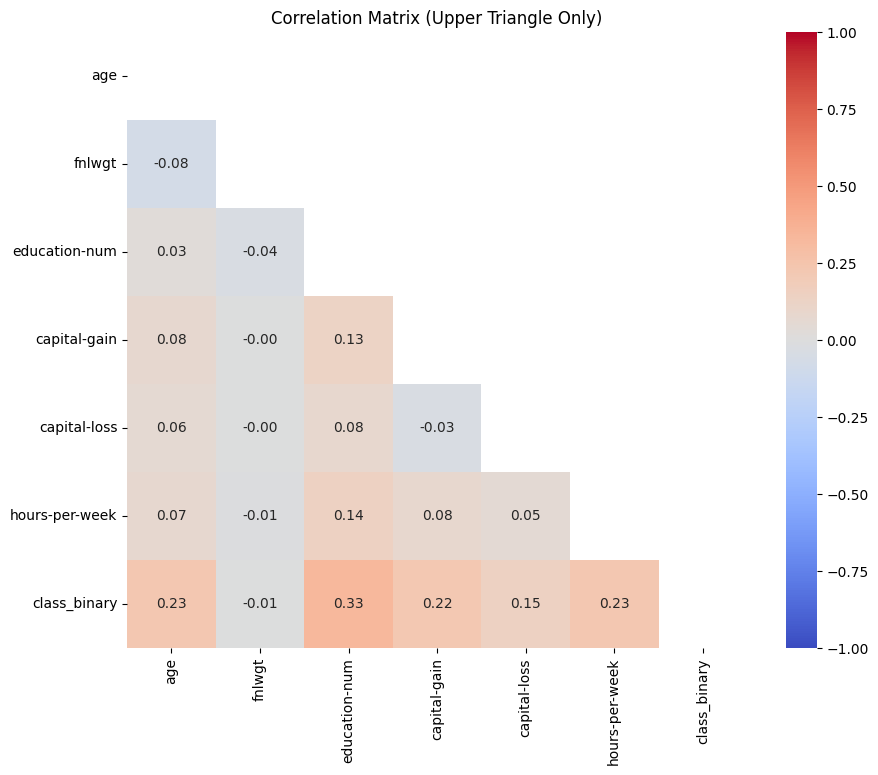

In [ ]:
corr = df.corr(numeric_only=True)

# Mask lower triangle (including diagonal)
mask = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(10, 8))
sns.heatmap(
    corr,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Matrix (Upper Triangle Only)")
plt.show()

- Remember not to drop columns just yet just loosely be aware they maybe be a possibility of dropping some collinear columns later in the train,test split.

comments:

possible actions:

- Redundant information
- possibility that drops will be made later?

### 6. Outliers & Anomalies

Are outliers real or errors?

- Errors hurt model, uses domain knowledge to determine this and decide whether to remove or handle them.
  e.g. height of 5 year old is being 7 feet like tall is likely an error
- Meaningful extremes are important e.g. very high incomes because you want see how your model performs on the full ranges of scenarios it'd enouter in production.

In [ ]:
# IQR-based outlier count per column
numeric_data = df.select_dtypes(include='number')

Q1 = numeric_data.quantile(0.25,numeric_only=True)
Q3 = numeric_data.quantile(0.75,numeric_only=True)
IQR = Q3 - Q1

outliers = ((numeric_data < (Q1 - 1.5 * IQR)) | (numeric_data > (Q3 + 1.5 * IQR))).sum()
outliers.sort_values(ascending=False)

hours-per-week    13486
class_binary      11681
capital-gain       4035
capital-loss       2282
education-num      1787
fnlwgt             1453
age                 215
dtype: int64

comments:

possible actions later on:

Do extreme values exist that could:
- distort model learning?

Are outliers:
- genuine signal (e.g. high-value customers)?
- or data issues?

## We have now our EDA

# Train/Test Split

In [ ]:


X = df.drop(["class","class_binary"],axis=1)
y = df["class_binary"]


X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

NameError: name 'df' is not defined

# Modelling

create a baseline models:

In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_score

Majority Vote Baselines:

In [ ]:
# Majority baseline
dummy_majority = DummyClassifier(strategy="most_frequent")
dummy_majority.fit(X_train, y_train)
y_pred_majority = dummy_majority.predict(X_test)

print("MAJORITY")
print("Accuracy:", accuracy_score(y_test, y_pred_majority))
print("F1:", f1_score(y_test, y_pred_majority))
print("Recall:", recall_score(y_test, y_pred_majority))
print("Precision:", precision_score(y_test, y_pred_majority))

MAJORITY
Accuracy: 0.7624513219922116
F1: 0.0
Recall: 0.0
Precision: 0.0


/opt/jupyterhub/env/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


A model that simply predicts the most common label would achieve a _____% accuracy, so we shouldnt overly rely on accuracy as the sole metric.

Also, the recall,precision and f1 are 0 since it fails to detect the minority/majority class

Stratified Sample Baselines:

In [ ]:
from sklearn.dummy import DummyClassifier

dummy_stratified = DummyClassifier(strategy="stratified", random_state=42)
dummy_stratified.fit(X_train, y_train)
y_pred_stratified = dummy_stratified.predict(X_test)

print("\nSTRATIFIED")
print("Accuracy:", accuracy_score(y_test, y_pred_stratified))
print("F1:", f1_score(y_test, y_pred_stratified))
print("Recall:", recall_score(y_test, y_pred_stratified))
print("Precision:", precision_score(y_test, y_pred_stratified))


STRATIFIED
Accuracy: 0.6355810616929699
F1: 0.22391968572675688
Recall: 0.22131147540983606
Precision: 0.22659010600706714


The Stratified Baseline achieves an recall,precision,f1 ~ 0.22 representing the performance of random guessing, a model that achieves below/above these value is no better than random/non-random guessing and hasn't learned any meaningful patterns.

In [ ]:
from pycaret.classification import *

In [ ]:
exp_setup = setup(data=X, target=y, session_id=123 , fold=5, n_jobs=1, train_size=0.8)

,Description,Value
0,Session id,123
1,Target,class_binary
2,Target type,Binary
3,Original data shape,"(48790, 15)"
4,Transformed data shape,"(48790, 65)"
5,Transformed train set shape,"(39032, 65)"
6,Transformed test set shape,"(9758, 65)"
7,Numeric features,6
8,Categorical features,8
9,Rows with missing values,7.4%


## Interpreting The Preprocessing Steps From Output

Look at the orignal data shape and the transformed data shape:

how many more columns were added?
which transformation step increased the columns count?:
  
- scaling
- label_encoding
- one hot encoding
  

Look at the imputation types used to handle missing values:
- For missing numerical features which imputation method was used?

Look at the categorical imputation types

which case does the mean not make sense:
- if the column contains outliers the mean can be distorted
- we should default to the median instead always
- we use the median imputation instead if outliers are present

Stratified K folds was used, what is the benefit of this? in the classification context?

In [ ]:
best_model = compare_models(budget_time =10)

,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC,TT (Sec)
lightgbm,Light Gradient Boosting Machine,0.8727,0.9289,0.6549,0.7787,0.7112,0.6304,0.6345,0.4940
xgboost,Extreme Gradient Boosting,0.8724,0.9282,0.6597,0.7742,0.7122,0.6310,0.6344,0.5280
gbc,Gradient Boosting Classifier,0.8673,0.9218,0.6054,0.7917,0.6859,0.6037,0.6126,3.0180
ada,Ada Boost Classifier,0.8614,0.9162,0.6106,0.7638,0.6784,0.5915,0.5977,1.1240
rf,Random Forest Classifier,0.8553,0.9044,0.6202,0.7346,0.6724,0.5804,0.5840,2.4400
lr,Logistic Regression,0.8450,0.8824,0.5749,0.7215,0.6398,0.5427,0.5484,29.8020
lda,Linear Discriminant Analysis,0.8418,0.8920,0.5607,0.7169,0.6292,0.5305,0.5370,0.7660
ridge,Ridge Classifier,0.8407,0.8920,0.5013,0.7505,0.6010,0.5064,0.5225,0.5860
et,Extra Trees Classifier,0.8347,0.8806,0.6063,0.6717,0.6371,0.5305,0.5318,2.4640
dt,Decision Tree Classifier,0.8175,0.7514,0.6245,0.6175,0.6210,0.5008,0.5008,0.4360


our class is imbalanced so like accuracy the AUC is not reliable rather. Instead we select base on the metric that aligns with our business problem ***

# Interpreting The Recall And Precision

For your best model and metric of focus:

let Y be your percentage recall and X the percentage precision, fill in the summary statment about your model output

> Add blockquote



We detect Y% of true cases Salary with X% confidence in each alert

Discuss how this is relevant to your business problem context

Additionally:

# Confusion Matrix

now that we've interpreted the recall and precision values as percentages:

let us more describe more concretely what has happened using the confusion matrix

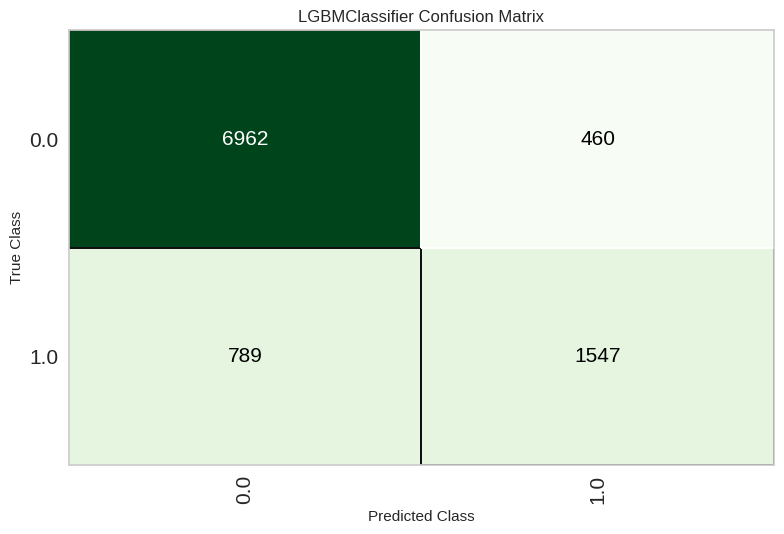

In [ ]:
plot_model(best_model, plot='confusion_matrix')

Fill in the statements below to evaluate the confusion matrix:

- The count of True Positives (predicted class 1 and is actually class 1) is _______
- The count of True Negative  (predicted class 0 and is actually class 0) is _______
- Of the _____________ Total Positive predictions _______________ of out of  _______ were correct
- Of the _____________ Total Negative predictions _______________ of out of  _______ were correct

suppose you want to improve your model with respect to precision,recall or f1

# Hyperparameter tuning

suppose you want to improve your model with respect to precision,recall or f1 you use Pycaret hyperparameter tuning like in the below commented out code (outputs alot of print statements be careful)

In [ ]:
#Tune the hyperparameters of the best model

# tuned_model = tune_model(best_model,optimize='recall')
# print(tuned_model)

 ### Baseline Model And Tuning Attempt Done ✅

# Evaluate On Test Set

lets get the metrics for the evaluation on the test set

In [ ]:
# use best_model if you didn't run the cell above
preds = predict_model(tuned_model)

NameError: name 'predict_model' is not defined

let see what how our model made its predictions

In [ ]:
evaluate_model(tuned_model)

interactive(children=(ToggleButtons(description='Plot Type:', icons=('',), options=(('Pipeline Plot', 'pipelin…

# Saving your model

In [ ]:
# finalize for production
final_model = finalize_model(tuned_model)

# save
save_model(final_model, 'my_model')

Transformation Pipeline and Model Successfully Saved


(Pipeline(memory=Memory(location=None),
          steps=[('numerical_imputer',
                  TransformerWrapper(exclude=None,
                                     include=['age', 'fnlwgt', 'education-num',
                                              'capital-gain', 'capital-loss',
                                              'hours-per-week'],
                                     transformer=SimpleImputer(add_indicator=False,
                                                               copy=True,
                                                               fill_value=None,
                                                               keep_empty_features=False,
                                                               missing_values=nan,
                                                               strategy='mean'))),
                 ('categorical_imputer',
                  Trans...
                  LGBMClassifier(boosting_type='gbdt', class_weight=None,
           

# Further Considerations (To covered in the optional session)

Improving the model parameters is just one way to improve the model with respect to the desired metric however doesnt guarantee you'll reach a desired score e.g. you may require precisely 90% precision.

in the optional session we will show you how BEAT the Pycaret model using  adjust the model threshold itself to reach the desired metrics aswell as advanced evaluation methods

- PR Curve
- ROC - AUC
- Probability Calibration
- Threshold Tuning

additionally:

- interpretting learning curves
